In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats
pd.set_option('display.max_columns',None)


In [2]:
#scaling, normalization
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#kmeans, dbscan, hierarchical (sklearn)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering 
#evaluation
from sklearn.metrics import silhouette_score
#import dataset
from sklearn.datasets import load_iris

#distance matrix (dbscan elbow, hierarchical)
from scipy.spatial.distance import pdist, squareform

# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [ ]:
car_data = pd.read_csv(r"C:\Users\X390\Desktop\UNI\Data Mining\dataset progetto\seller_info_dm1_2627.csv")


In [ ]:
car_data

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.00,68.9,195.35,77.10,0.133333,0.000000,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.90,64.7,180.30,72.50,0.058824,0.000000,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.50,58.1,188.20,72.00,0.111111,0.000000,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.50,57.9,190.05,72.05,0.000000,0.000000,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.10,70.2,187.60,74.00,0.000000,0.000000,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13838,59623.0,185,42625.0,0.0,28.0,12.0,2020.0,0.0,1.0,290.0,3500.0,20.0,27.0,36.60,42.0,17.20,65.7,191.45,74.80,0.000000,0.735135,0.0,0.000000,65,369,suv_crossover,gasoline,a,NaN,gray,franchise,mixed,high
13839,49530.0,155,31590.0,0.0,27.0,8.0,2020.0,0.0,1.0,305.0,3600.0,22.0,29.0,39.70,42.3,19.00,67.0,198.40,78.60,0.484848,0.787097,0.0,0.000000,64,370,suv_crossover,gasoline,a,fwd,white,franchise,mixed,medium
13840,49610.0,296,29992.5,0.0,48.0,9.0,2020.0,0.0,1.0,277.0,3300.0,21.0,26.0,38.90,42.2,19.00,69.3,193.40,80.50,0.468468,0.625000,0.0,0.009009,98,393,suv_crossover,gasoline,a,NaN,unknown,franchise,mixed,medium
13841,372531.0,235,32864.0,0.0,51.0,15.0,2020.0,0.0,1.0,285.0,3600.0,19.0,26.0,38.60,41.1,21.10,69.3,193.10,80.00,0.413333,0.685106,0.0,0.013333,71,435,suv_crossover,gasoline,a,NaN,black,franchise,mixed,medium


In [ ]:
killcolumns = ['dominant_transmission','dominant_fuel_type','pct_salvage','pct_theft_title','dominant_wheel_system']
c_d_clean = car_data.drop(killcolumns,axis=1)

In [ ]:
pricebyseller = pd.DataFrame(car_data.loc[:,['seller_rating_class','price_median','mileage_median']])
pricebyseller

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


In [ ]:
def iqr(sr: pd.Series):
    Q1 = sr.quantile(0.25)
    Q3 = sr.quantile(0.75)
    return (Q3-Q1)

def upper(sr: pd.Series):
    upperlimit = sr.quantile(0.75)+(1.5*iqr(sr))
    return upperlimit


def lower(sr: pd.Series):
    lowerlimit = sr.quantile(0.25)-(1.5*iqr(sr))
    return lowerlimit


In [ ]:
r_p_clean = pricebyseller[pricebyseller['price_median'] <=upper(pricebyseller['price_median'])]
r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


<Axes: xlabel='price_median', ylabel='mileage_median'>

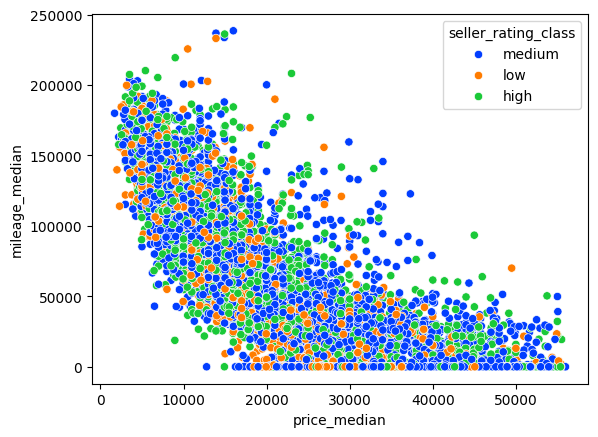

In [ ]:
marks= list(r_p_clean['seller_rating_class'].unique())
sns.scatterplot(data=r_p_clean, x="price_median", y="mileage_median", hue='seller_rating_class', palette="bright")

In [ ]:
x = r_p_clean.drop('seller_rating_class',axis=1).dropna().reset_index(drop=True)
scaler = StandardScaler()
scaler.fit(x)
X_scal = scaler.transform(x)



In [ ]:
X_scal

array([[-1.36393874,  2.71930313],
       [-0.98793864,  0.68520614],
       [-1.28120996,  1.91495413],
       ...,
       [ 0.67517237, -1.00171264],
       [ 0.92655404, -1.00159707],
       [ 0.34403841, -1.00178969]], shape=(13671, 2))

In [ ]:
sse_list = []
for k in range(3,51):
    kmeans = KMeans(n_clusters=k,n_init=10,max_iter=100, random_state=94)
    kmeans.fit(X_scal)
    sse_list.append(kmeans.inertia_)

<Axes: >

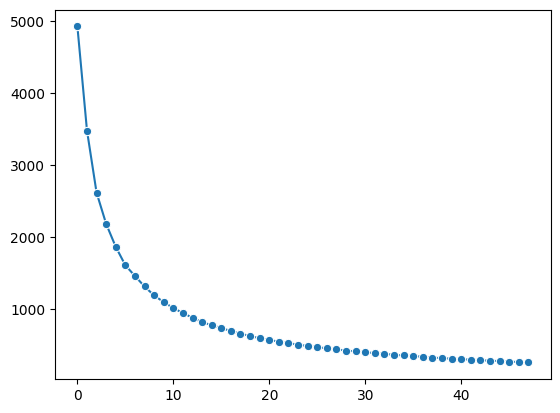

In [ ]:
sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o')


In [ ]:
kmeans = KMeans(n_clusters=6,n_init=10,max_iter=100, random_state=94)
kmeans.fit(X_scal)

,n_clusters,6
,init,'k-means++'
,n_init,10
,max_iter,100
,tol,0.0001
,verbose,0
,random_state,94
,copy_x,True
,algorithm,'lloyd'


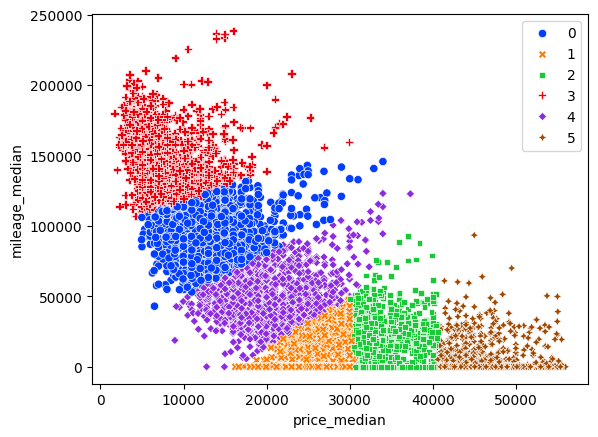

In [ ]:
sns.scatterplot(data=x,
                x="price_median",
                y="mileage_median",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

In [ ]:
#pyclustering.github.io

In [ ]:
kmeans.cluster_centers_

array([[-0.86273447,  0.8327583 ],
       [ 0.35279063, -0.85701469],
       [ 1.08383336, -0.81462021],
       [-1.2637121 ,  1.68960242],
       [-0.17170042, -0.17454933],
       [ 2.0783956 , -0.89344387]])

In [ ]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers

array([[ 12425.19097736,  95249.48616601],
       [ 26309.97549896,   7521.3039798 ],
       [ 34660.58119516,   9722.30433686],
       [  7844.87584054, 139734.38304515],
       [ 20318.78267938,  42952.95428454],
       [ 46021.33579154,   5630.00491642]])

In [ ]:
r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


In [ ]:

r_p_clean = r_p_clean.dropna(axis=0).reset_index(drop=True)

r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13666,high,42625.0,12.0
13667,medium,31590.0,8.0
13668,medium,29992.5,9.0
13669,medium,32864.0,15.0


In [ ]:
r_p_clean['kmeans_labels'] = kmeans.labels_
r_p_clean['kmeans_labels'] = r_p_clean['kmeans_labels'].map({0:"A",1:"B",2:"C",3:"D",4:"E",5:"F"})

r_p_clean

,seller_rating_class,price_median,mileage_median,kmeans_labels
0,medium,6700.0,193193.5,D
1,medium,10995.0,87589.0,A
2,low,7645.0,151434.0,D
3,medium,23449.0,31186.0,E
4,medium,8990.0,144471.5,D
...,...,...,...,...
13666,high,42625.0,12.0,F
13667,medium,31590.0,8.0,C
13668,medium,29992.5,9.0,B
13669,medium,32864.0,15.0,C


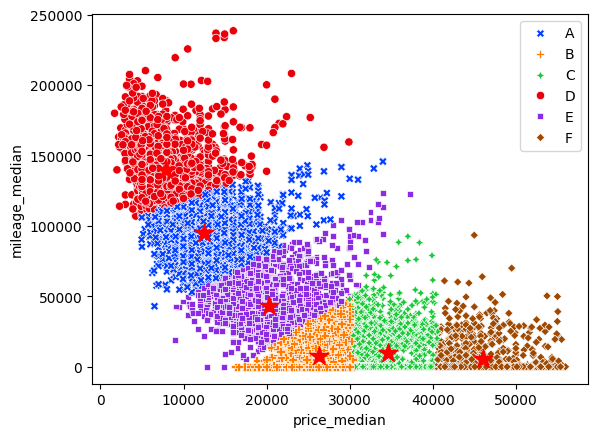

In [ ]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue='kmeans_labels', 
                style='kmeans_labels',
                palette="bright", 
                hue_order=["A", "B", "C","D","E","F"]
               )
plt.legend()
plt.scatter(centers[:,0], centers[:,1], c='red', marker='*', s=200)
plt.show()

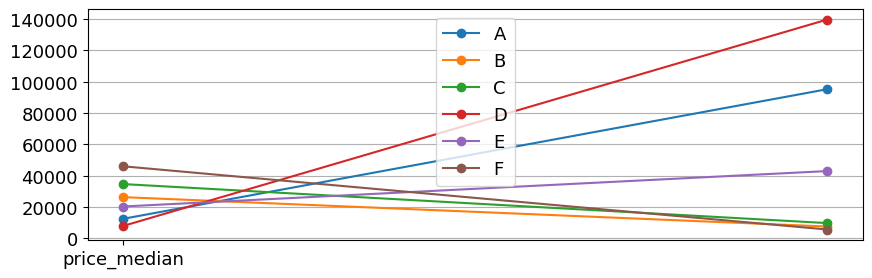

In [ ]:
plt.figure(figsize=(10,3))

clust_name = ['A','B','C','D','E','F']

for i in range(len(centers)):
    plt.plot(centers[i],marker='o', label=clust_name[i])

plt.xticks(range(0,len(x.columns) - 1), x.columns[:-1], fontsize=13)
plt.yticks(fontsize=13)

plt.legend(fontsize=13, loc='best')
plt.grid(axis='y')

In [ ]:
y = np.array(r_p_clean['seller_rating_class'])
y


array(['medium', 'medium', 'low', ..., 'medium', 'medium', 'low'],
      shape=(13671,), dtype=object)

In [ ]:
y_map = {'low':0,'medium':1,'high':2}
y_mapped = pd.DataFrame(y).iloc[:,0].map(y_map)

y_mapped

0        1
1        1
2        0
3        1
4        1
        ..
13666    2
13667    1
13668    1
13669    1
13670    0
Name: 0, Length: 13671, dtype: int64

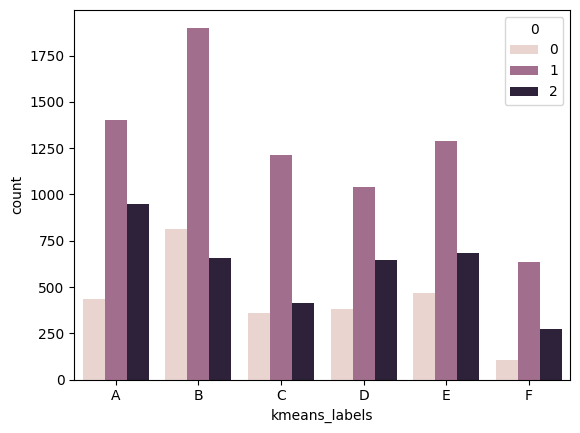

In [ ]:
sns.countplot(data=r_p_clean, x='kmeans_labels', hue=y_mapped, order=['A','B','C','D','E','F'])
plt.show()

In [ ]:
y_mapped.groupby(r_p_clean['kmeans_labels']).value_counts(normalize=True)

kmeans_labels  0
A              1    0.503767
               2    0.339433
               0    0.156799
B              1    0.563928
               0    0.241471
               2    0.194601
C              1    0.612091
               2    0.207053
               0    0.180856
D              1    0.503382
               2    0.312560
               0    0.184058
E              1    0.528062
               2    0.279394
               0    0.192544
F              1    0.624385
               2    0.270403
               0    0.105211
Name: proportion, dtype: float64

In [ ]:
kmeans.inertia_

2183.455816196532

In [ ]:
print('Silhouette',silhouette_score(X_scal, kmeans.labels_))

Silhouette 0.41482816218814644


In [ ]:
from sklearn.cluster import BisectingKMeans

In [ ]:
bkmeans = BisectingKMeans(n_clusters=6, n_init=10, max_iter=100, random_state=94)
bkmeans.fit(X_scal)

,n_clusters,6
,init,'random'
,n_init,10
,random_state,94
,max_iter,100
,verbose,0
,tol,0.0001
,copy_x,True
,algorithm,'lloyd'
,bisecting_strategy,'biggest_inertia'


In [ ]:
centers = scaler.inverse_transform(bkmeans.cluster_centers_)
centers

array([[ 46666.12679956,   5812.34163898],
       [ 36291.37951412,   7671.63230466],
       [ 27255.28968146,   6023.39348692],
       [ 21986.83052017,  36705.53673036],
       [  8269.36803464, 133645.43561747],
       [ 13836.59237123,  85203.57910228]])

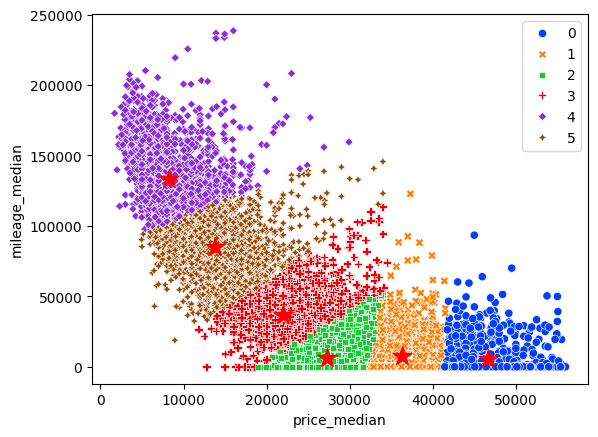

In [ ]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue=bkmeans.labels_, 
                style=bkmeans.labels_,
                palette="bright", 
               )
plt.legend()
plt.scatter(centers[:,0], centers[:,1], c='red', marker='*', s=200)
plt.show()

In [ ]:
print('SSE', bkmeans.inertia_)
print('Silhouette', silhouette_score(X_scal, bkmeans.labels_))

SSE 2318.654857243111
Silhouette 0.411761139163122


<h2>DBSCAN</h2>

In [ ]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan.fit(X_scal)

,eps,0.3
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


<Axes: xlabel='price_median', ylabel='mileage_median'>

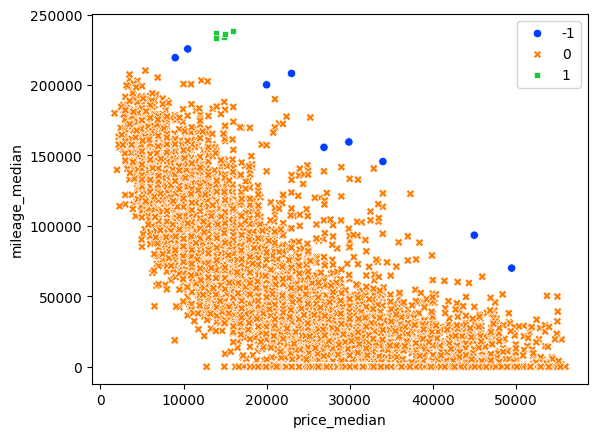

In [ ]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue=dbscan.labels_, 
                style=dbscan.labels_,
                palette="bright", 
               )

In [ ]:
dist = pdist(X_scal[0:1000],'mahalanobis') #scalate le distanze
dist = squareform(dist)

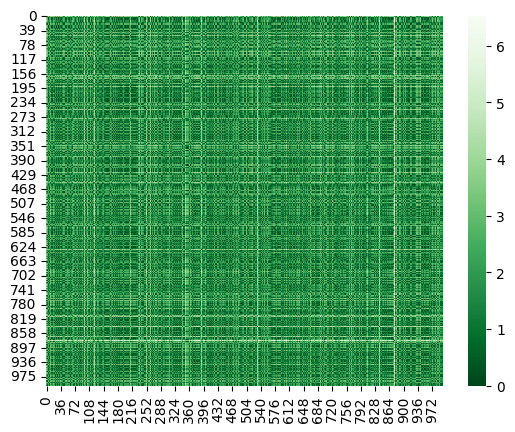

In [ ]:
sns.heatmap(dist, cmap="Greens_r", annot=False)
plt.show()

In [ ]:
k=16
kth_distances=[]

for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

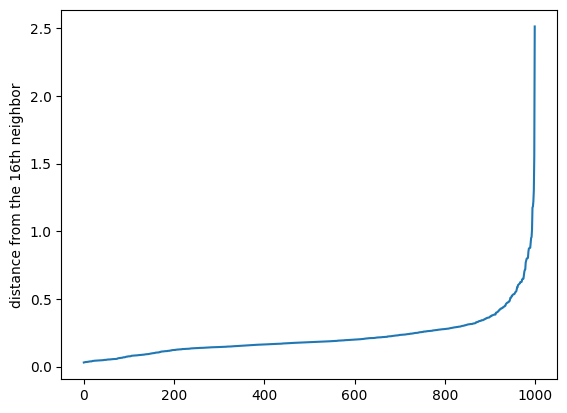

In [ ]:
plt.plot(range(0, len(kth_distances)), sorted(kth_distances))
plt.ylabel('distance from the {}th neighbor'.format(k))
         
plt.show()

In [ ]:
from sklearn.cluster import HDBSCAN

In [ ]:
hdbscan = HDBSCAN(min_cluster_size=7, allow_single_cluster=True, cluster_selection_epsilon=0.2, alpha=0.3)
hdbscan.fit(X_scal)

,min_cluster_size,7
,min_samples,None
,cluster_selection_epsilon,0.2
,max_cluster_size,None
,metric,'euclidean'
,metric_params,None
,alpha,0.3
,algorithm,'auto'
,leaf_size,40
,n_jobs,None
,cluster_selection_method,'eom'


<Axes: xlabel='price_median', ylabel='mileage_median'>

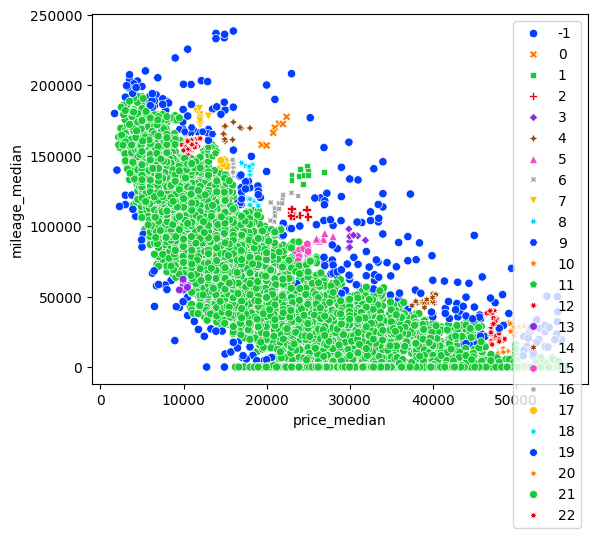

In [ ]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue=hdbscan.labels_, 
                style=hdbscan.labels_,
                palette="bright", 
               )

In [ ]:
from sklearn.cluster import OPTICS, cluster_optics_dbscan

In [ ]:
optics = OPTICS(min_samples = 4, max_eps = np.inf, min_cluster_size=200, algorithm='kd_tree')
optics.fit(X_scal)

C:\Users\X390\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\cluster\_optics.py:1084: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]


,min_samples,4
,max_eps,inf
,metric,'minkowski'
,p,2
,metric_params,None
,cluster_method,'xi'
,eps,None
,xi,0.05
,predecessor_correction,True
,min_cluster_size,200
,algorithm,'kd_tree'


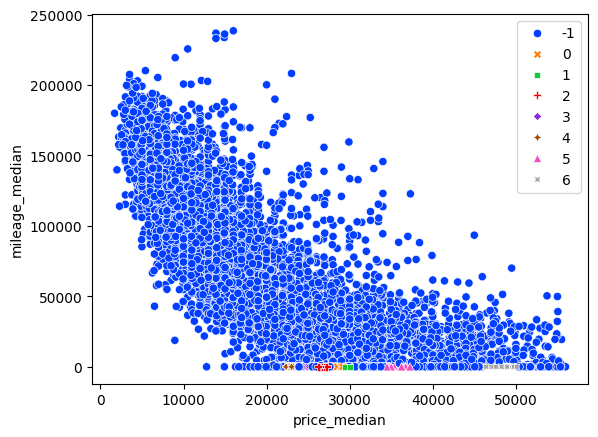

In [ ]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue=optics.labels_, 
                style=optics.labels_, 
                palette="bright")
plt.show()

In [ ]:
def get_linkage_matrix(model):
    # Create linkage matrix 
    
    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix

def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scal,method="ward")

NameError: name 'X_minmax' is not defined